# Анализ системы метрик приложения Procrastinate Pro+ 

### Введение

- Автор: Ивченко Юлия
- Дата: 02.06.2026

Приложение Procrastinate Pro+ предоставляет пользователям доступ к развлекательному контенту: видео, подкастам и блогам. Пользователи могут выбрать несколько пакетов контента. Пакеты различаются по цене, объёму и содержанию.

К началу лета в приложении появился новый вид контента — спортивный. С его помощью менеджеры стремятся расширить аудиторию, добавив в неё пользователей, которые увлекаются спортом и здоровым образом жизни.

К запуску нового контента была скорректирована маркетинговая стратегия привлечения пользователей. Согласно бизнес-модели продукта, привлечение должно окупиться за первые 28 дней (4 недели).

После запуска нового контента и изменения стратегии интерес к продукту в целом вырос, но выручка начала стагнировать. 


Цель: разобраться, почему запуска нового контента и изменения стратегии интерес к продукту в вырос, но выручка начала стагнировать

Задачи:
- провести анализ юнит-экономики продукта в динамике за первые 28 дней;
- разобраться в причинах стагнации выручки;
- определить, какие источники привлечения приносят прибыль, а какие не выходят на уровень окупаемости;
- дать рекомендации отделу маркетинга.


### Данные

Имеем данные о посещениях приложения, покупках и расходах на маркетинг. Данные собраны в трёх датасетах.

1. Датасет `path_ppro_visits ` — информация о посещениях приложения пользователями, которые зарегистрировались с 1 апреля 2024 года по 30 ноября 2024 года:
    - `user_id` — уникальный идентификатор пользователя;
    - `region` — страна пользователя;
    - `device` — категория устройства пользователя;
    - `channel` — идентификатор рекламного источника, из которого пришёл пользователь;
    - `session_start` — дата и время начала сессии;
    - `session_end` — дата и время окончания сессии.

2. Датасет `path_ppro_orders ` — информация о покупках:
    - `user_id` — уникальный идентификатор пользователя, который сделал покупку;
    - `event_dt` — дата и время покупки;
    - `revenue` — выручка.

3. Датасет `path_ppro_costs ` — информация о затратах на маркетинг:
    - `dt` — дата
    - `channel` — идентификатор рекламного источника;
    - `costs` — затраты на этот рекламный источник в этот день.
    
### План проекта
- Загрузить и предобработать данные.
- Подготовить данные для когортного анализа.
- Рассчитать и проанализировать метрики вовлечённости в продукт.
- Рассчитать и проанализировать финансовые метрики CAC, LTV и ROI за первые 28 дней с момента привлечения.
- Исследовать метрики в разрезе источника привлечения.
- Рассчитать период окупаемости маркетинговых вложений.
- Сформулировать выводы и рекомендации.


## Загрузка и предобработка данных

Загрузим данные и получим основную информацию о них. Проведем необходимую предобработку. Основную информацию о данных и предобработке зафиксируем в кратком промежуточном выводе.

In [1]:
# Импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

In [2]:
# Выгружаем данные с информацией о посещениях приложения в переменную df_visits 
df_visits = pd.read_csv('path_ppro_visits ')
# Выгружаем данные с информацией о покупках в переменную ppro_orders.csv
df_orders = pd.read_csv('path_ppro_orders ')
# Выгружаем данные с информацией о затратах на маркетинг в переменную df_costs 
df_costs = pd.read_csv('path_ppro_costs ')

Выведем информацию о датафрейме df_visits, которая необходима для принятия решений о предобработке.

In [3]:
# Выводим первые строки датафрейма df_visits на экран 
display(df_visits.head())
# Выводим информацию о датафрейме df_visits на экран 
display(df_visits.info())
# Выводим количество пропусков
print(f'Количество пропусков: \n{df_visits.isna().sum()}')
# Выводим количество дубликатов по столбцам 'user_id' и 'session_start'
print(f"Количество дубликатов: {df_visits.duplicated(subset=['user_id', 'session_start'], keep=False).sum()}")
# Выводим уникальные значеиня столбцов 'region', 'device', 'channel'
print(f'Уникальные значения region: {df_visits["region"].unique()}\n'
      f'Уникальные значения device: {df_visits["device"].unique()}\n'
      f'Уникальные значения channel: {df_visits["channel"].unique()}')

,user_id,region,device,channel,session_start,session_end
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161865 entries, 0 to 161864
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user_id        161865 non-null  int64 
 1   region         161865 non-null  object
 2   device         161865 non-null  object
 3   channel        161865 non-null  object
 4   session_start  161865 non-null  object
 5   session_end    161865 non-null  object
dtypes: int64(1), object(5)
memory usage: 7.4+ MB


None

Количество пропусков: 
user_id          0
region           0
device           0
channel          0
session_start    0
session_end      0
dtype: int64
Количество дубликатов: 0
Уникальные значения region: ['India']
Уникальные значения device: ['desktop' 'tv' 'mobile']
Уникальные значения channel: ['MediaTornado' 'RocketSuperAds' 'FaceBoom' 'TipTop']


Датасет df_visits содержит 6 столбцов и 161865 строк с информацией о посещениях приложения пользователями.

После первичного анализа данных можно сделать следующие выводы:

- Названия столбцов приведены к единому виду (в стиле snake case)
- Данные, представленные в столбцах: `region`, `device`, `channel` -  содержат текстовые значения и хранятся в типах данных object. Данные представлены верно.
- Значения в столбцах `session_start`, `session_end` содержат дату, проэтому заменим тип данных с object на datetime.
  
Пропусов в столбцах нет, дубликатов нет.

Выведем информацию о датафрейме df_orders, которая необходима для принятия решений о предобработке.

In [4]:
# Выводим первые строки датафрейма df_orders на экран 
display(df_orders.head())
# Выводим информацию о датафрейме df_orders на экран 
display(df_orders.info())
# Выводим количество пропусков
print(f'Количество пропусков: \n{df_orders.isna().sum()}')
# Выводим количество дубликатов по столбцам 'user_id' и 'session_start'
print(f"Количество дубликатов: {df_orders.duplicated(subset=['user_id', 'event_dt'], keep=False).sum()}")


,user_id,event_dt,revenue
0,771951256319,2024-04-01 05:56:26,2.99
1,829942381059,2024-04-01 14:55:02,2.99
2,727879856738,2024-04-01 22:15:09,14.99
3,481270888930,2024-04-01 06:05:14,2.99
4,844695029762,2024-04-01 01:19:52,2.99


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33893 entries, 0 to 33892
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   33893 non-null  int64  
 1   event_dt  33893 non-null  object 
 2   revenue   33893 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 794.5+ KB


None

Количество пропусков: 
user_id     0
event_dt    0
revenue     0
dtype: int64
Количество дубликатов: 0


Датасет df_orders содержит 3 столбца и 33893 строк с информацией о покупках.

После первичного анализа данных можно сделать следующие выводы:

- Названия столбцов приведены к единому виду (в стиле snake case)
- Данные, представленные в столбцах: `revenue ` -  хранятся в типах данных float64. Данные представлены верно.
- Значения в столбцах `event_dt` содержат дату, проэтому заменим тип данных с object на datetime.
  
Пропусов в столбцах нет, дубликатов нет.

Выведем информацию о датафрейме df_costs, которая необходима для принятия решений о предобработке.

In [5]:
# Выводим первые строки датафрейма df_costs на экран 
display(df_costs.head())
# Выводим информацию о датафрейме df_costs на экран 
display(df_costs.info())
# Выводим количество пропусков
print(f'Количество пропусков: \n{df_costs.isna().sum()}')
# Выводим количество дубликатов по столбцам 'user_id' и 'session_start'
print(f"Количество дубликатов: {df_costs.duplicated(subset=['dt', 'channel'], keep=False).sum()}")
# Выводим уникальные значеиня столбцов 'region', 'device', 'channel'
print(f"Уникальные значения region: {df_costs['channel'].unique()}\n")

,dt,channel,costs
0,2024-04-01,FaceBoom,124.938874
1,2024-04-02,FaceBoom,88.147779
2,2024-04-03,FaceBoom,120.779457
3,2024-04-04,FaceBoom,98.981253
4,2024-04-05,FaceBoom,109.044760


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   dt       976 non-null    object 
 1   channel  976 non-null    object 
 2   costs    976 non-null    float64
dtypes: float64(1), object(2)
memory usage: 23.0+ KB


None

Количество пропусков: 
dt         0
channel    0
costs      0
dtype: int64
Количество дубликатов: 0
Уникальные значения region: ['FaceBoom' 'MediaTornado' 'RocketSuperAds' 'TipTop']



Датасет df_costs содержит 3 столбца и 976 строк с информацией о затратах на маркетинг.

После первичного анализа данных можно сделать следующие выводы:

- Названия столбцов приведены к единому виду (в стиле snake case)
- Данные, представленные в столбцах: `channel` -  содержат текстовые значения и хранятся в типах данных object. Данные представлены верно.
- Данные, представленные в столбцах: `costs` -  хранятся в типах данных float64. Данные представлены верно.
- Значения в столбцах `dt` содержат дату, проэтому заменим тип данных с object на datetime.
  
Пропусов в столбцах нет, дубликатов нет.

Приведем значения, в которых содержится дата к типу данных datetime

In [6]:
# значения в столбцах приведем в типу datetime
df_visits['session_start']=pd.to_datetime(df_visits['session_start']).dt.normalize()
df_visits['session_end']=pd.to_datetime(df_visits['session_end']).dt.normalize()
df_orders['event_dt']=pd.to_datetime(df_orders['event_dt']).dt.normalize()
df_costs['dt']=pd.to_datetime(df_costs['dt']).dt.normalize()

В результате предобработки данных в столбцах `session_start`, `session_end`, `event_dt` и `dt` поменяли тип данных с object на datetime. Строки не удаляли, так как  дубликатов и пропусков в столбцах не было.

Проверим интервал дат

In [7]:
display(df_visits['session_start'].min(), df_visits['session_start'].max())
display(df_orders['event_dt'].min(), df_orders['event_dt'].max())
display(df_costs['dt'].min(), df_costs['dt'].max())

Timestamp('2024-04-01 00:00:00')

Timestamp('2024-11-30 00:00:00')

Timestamp('2024-04-01 00:00:00')

Timestamp('2024-11-30 00:00:00')

Timestamp('2024-04-01 00:00:00')

Timestamp('2024-11-30 00:00:00')

Все таблицы содержат данные с 1апреля по 30ноября

In [8]:
display(f'покупетелей без визитов:{len(set(df_orders['user_id'])-set(df_visits['user_id']))}')

'покупетелей без визитов:0'

In [9]:
channel_dist=df_visits.groupby('channel')['user_id'].nunique()
display(channel_dist)

channel
FaceBoom          29109
MediaTornado      14804
RocketSuperAds    14972
TipTop            18709
Name: user_id, dtype: int64

Пользователей по каналу FaceBoom больше, чем в остальных каналах, а в других каналах пользователи распределены равномерно

## Подготовка данных к когортному анализу

Подготовьте данные к когортному анализу с учётом того, что вы будете изучать окупаемость привлечения пользователей за первые 28 дней.

Для каждого пользователя найдите:
- дату первой сессии (дата привлечения пользователя, `first_dt`);
- канал привлечения (`first_channel`);
- стоимость привлечения пользователя (`cac`).

Результаты сохраните в новой таблице, например, `profiles`.

Добавьте к данным с событиями и покупками информацию о первом источнике привлечения и дату привлечения пользователя из созданной таблицы. После этого рассчитайте дневной лайфтайм для каждого события или покупки и добавьте в таблицу в виде целого числа. В дальнейшем при проведении когортного анализа используйте информацию о первом источнике привлечения пользователя.

In [10]:
# Находим дату первой сессии
min_date = df_visits.groupby('user_id')['session_start'].min().reset_index().rename(columns={'session_start': 'first_dt'})
first_sessions=df_visits.merge(min_date, on='user_id')
# Выбираем строки с первой сессией и берём канал
first_sessions = first_sessions[first_sessions['session_start'] == first_sessions['first_dt']][['user_id', 'channel', 'first_dt']].drop_duplicates(subset='user_id', keep='first').rename(columns={'channel': 'first_channel'})
# Присоединяем канал к основной таблице
profiles=first_sessions.copy()

# Считаем количество пользоталей, привлеченных за день с определенного канала
count_users=first_sessions.groupby(['first_dt', 'first_channel'])['user_id'].nunique().reset_index().rename(columns={'user_id': 'count_user'})
# Переименовываем столбцы
df_costs = df_costs.rename(columns={'dt': 'first_dt' , 'channel': 'first_channel'})
df_costs=df_costs.merge(count_users, on=['first_dt', 'first_channel'], how='left')
# Pасчитываем CAC
df_costs['cac']=df_costs['costs']/df_costs['count_user']
# Присоединяем CAC к основной таблице
profiles = profiles.merge(df_costs[['first_dt', 'first_channel', 'cac']], on=['first_dt', 'first_channel'], how='left')
display(profiles)

,user_id,first_channel,first_dt,cac
0,631105188566,MediaTornado,2024-04-01,0.249160
1,892885906464,RocketSuperAds,2024-04-01,0.886429
2,517003690029,MediaTornado,2024-04-01,0.249160
3,185156659289,MediaTornado,2024-04-01,0.249160
4,409503040345,RocketSuperAds,2024-04-01,0.886429
...,...,...,...,...
74851,173722594460,MediaTornado,2024-11-30,0.271968
74852,711873273862,FaceBoom,2024-11-30,1.177762
74853,797604836232,TipTop,2024-11-30,2.864337
74854,188139897674,MediaTornado,2024-11-30,0.271968


In [11]:
# Объединяем profiles с df_orders
orders = df_orders.merge(profiles, on='user_id', how='left')
# Считаем дневной лайфтайм для каждого события или покупки 
orders['lifetime']= (orders['event_dt']-orders['first_dt']).dt.days
display(orders)
# Объединяем profiles с df_visits
visits = df_visits.merge(profiles, on='user_id', how='left')
# Считаем дневной лайфтайм для каждого события или покупки 
visits['lifetime']= (visits['session_start']-visits['first_dt']).dt.days
display(visits)

,user_id,event_dt,revenue,first_channel,first_dt,cac,lifetime
0,771951256319,2024-04-01,2.99,FaceBoom,2024-04-01,0.939390,0
1,829942381059,2024-04-01,2.99,FaceBoom,2024-04-01,0.939390,0
2,727879856738,2024-04-01,14.99,FaceBoom,2024-04-01,0.939390,0
3,481270888930,2024-04-01,2.99,TipTop,2024-04-01,0.742467,0
4,844695029762,2024-04-01,2.99,FaceBoom,2024-04-01,0.939390,0
...,...,...,...,...,...,...,...
33888,397577560536,2024-11-30,2.99,RocketSuperAds,2024-11-30,0.394091,0
33889,610390409217,2024-11-30,7.99,TipTop,2024-11-30,2.864337,0
33890,74116424793,2024-11-30,2.99,FaceBoom,2024-11-30,1.177762,0
33891,691138256176,2024-11-30,2.99,FaceBoom,2024-11-30,1.177762,0


,user_id,region,device,channel,session_start,session_end,first_channel,first_dt,cac,lifetime
0,631105188566,India,desktop,MediaTornado,2024-04-01,2024-04-01,MediaTornado,2024-04-01,0.249160,0
1,892885906464,India,tv,RocketSuperAds,2024-04-01,2024-04-01,RocketSuperAds,2024-04-01,0.886429,0
2,517003690029,India,mobile,MediaTornado,2024-04-01,2024-04-01,MediaTornado,2024-04-01,0.249160,0
3,185156659289,India,mobile,MediaTornado,2024-04-01,2024-04-01,MediaTornado,2024-04-01,0.249160,0
4,409503040345,India,mobile,RocketSuperAds,2024-04-01,2024-04-01,RocketSuperAds,2024-04-01,0.886429,0
...,...,...,...,...,...,...,...,...,...,...
161860,173722594460,India,desktop,MediaTornado,2024-11-30,2024-11-30,MediaTornado,2024-11-30,0.271968,0
161861,711873273862,India,mobile,FaceBoom,2024-11-30,2024-11-30,FaceBoom,2024-11-30,1.177762,0
161862,797604836232,India,mobile,TipTop,2024-11-30,2024-11-30,TipTop,2024-11-30,2.864337,0
161863,188139897674,India,desktop,MediaTornado,2024-11-30,2024-11-30,MediaTornado,2024-11-30,0.271968,0


## Анализ месячной динамики основных метрик продукта

**Задача 1**. Начните анализ данных с изучения динамики активности пользователей и их вовлечённости в продукт. Рассчитайте по всем данным значения DAU, MAU и Stickiness и визуализируйте их. Активными считайте всех пользователей, которые взаимодействовали с приложением.

**Задача 2**. В разрезе каждого месяца привлечения новых пользователей рассчитайте:
- Среднюю стоимость привлечения пользователя (CAC).
- Значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения.

Здесь и далее при расчёте LTV и ROI учитывайте всех привлечённых пользователей когорты.

Визуализируйте метрики и сформулируйте небольшой промежуточный вывод. Сделайте акцент на общей динамике изменения метрик с учётом появления нового контента в начале лета.

**Задача 1.**

Изученим динамику активности пользователей и их вовлечённости в продукт. Рассчитаем по всем данным значения DAU, MAU и Stickiness и визуализируем их.

session_start
2024-04    5.384644
2024-05    5.318165
2024-06    5.667643
2024-07    5.660898
2024-08    5.687514
2024-09    5.989743
2024-10    5.931218
2024-11    6.158284
Freq: M, Name: user_id, dtype: float64

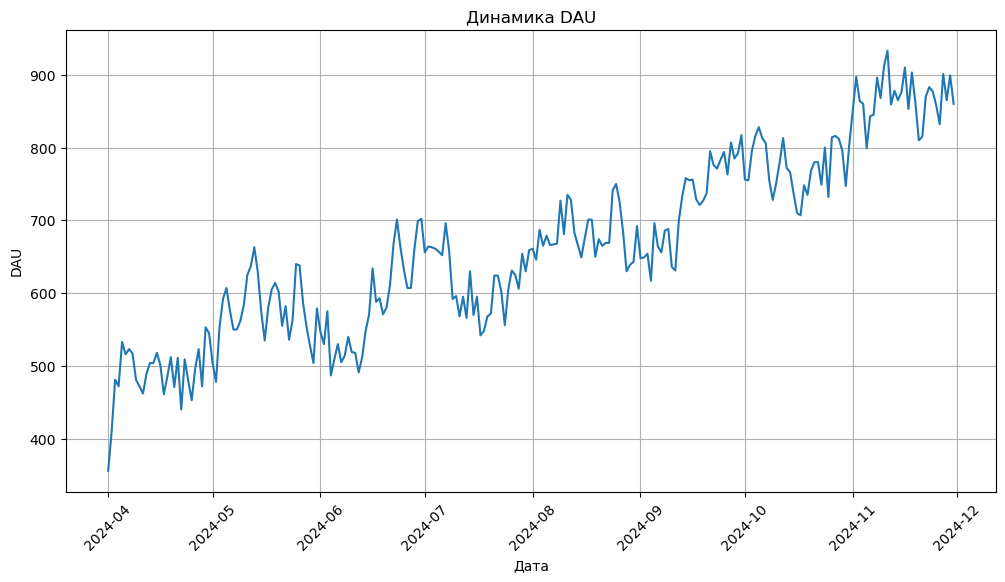

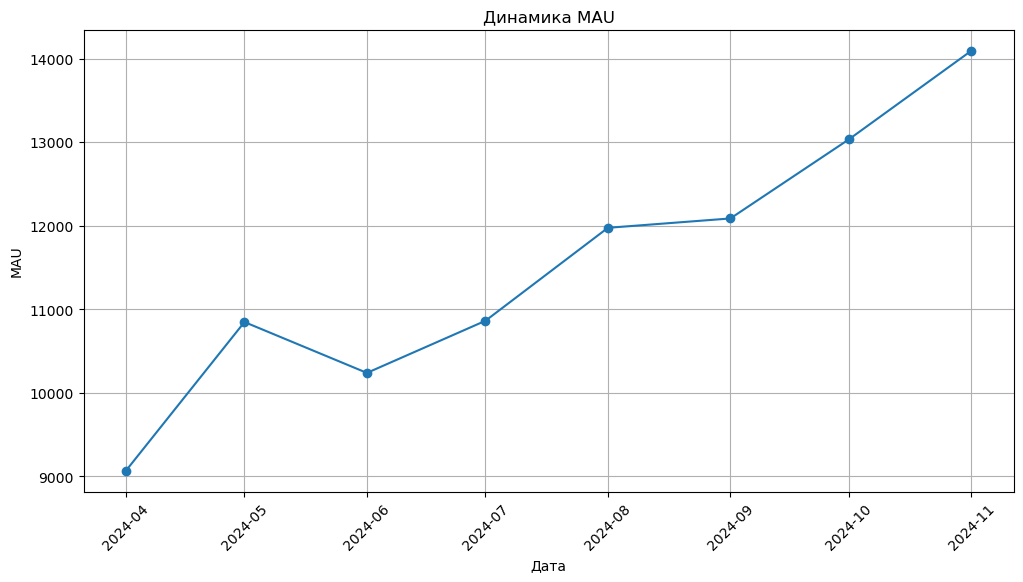

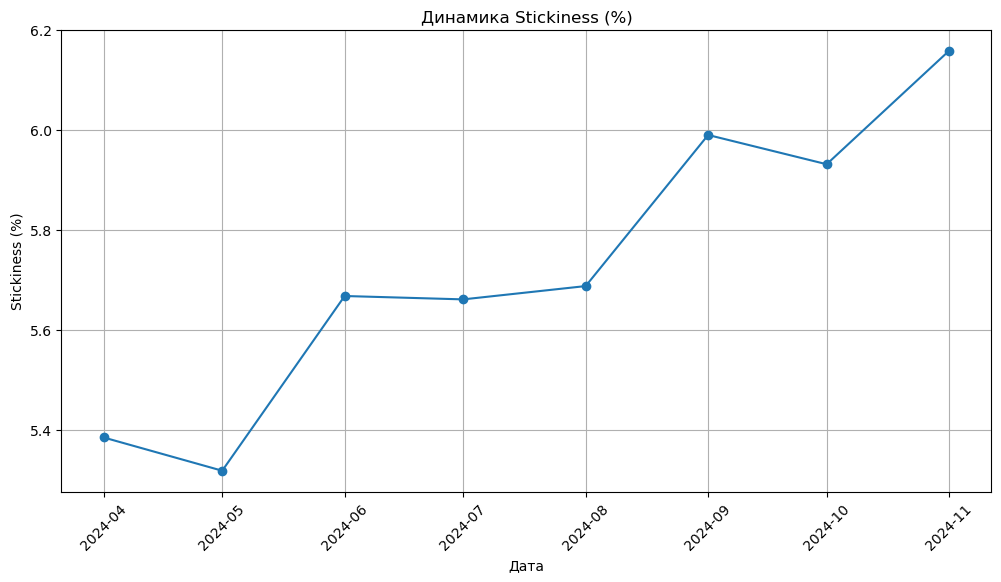

In [12]:
# DAU по дням
dau = visits.groupby('session_start')['user_id'].nunique().reset_index()
# MAU по месяцам
mau = visits.groupby(visits['session_start'].dt.to_period('M'))['user_id'].nunique()
# Средний DAU по месяцам 
dau_avg = dau.groupby(dau['session_start'].dt.to_period('M'))['user_id'].mean()

# Приводим MAU к тому же типу индекса (Period) и делим
Stickiness = (dau_avg / mau) * 100
display(Stickiness)
 
# Построение графика
plt.figure(figsize=(12, 6))

plt.plot(dau['session_start'], dau['user_id'])

plt.xticks(rotation=45)
plt.xlabel('Дата')
plt.ylabel('DAU')
plt.title('Динамика DAU')
plt.grid(True)
plt.show()

# Построение графика
plt.figure(figsize=(12, 6))

plt.plot(mau.index.to_timestamp(), mau.values, marker='o')

plt.xticks(rotation=45)
plt.xlabel('Дата')
plt.ylabel('МАU')
plt.title('Динамика МАU')
plt.grid(True)
plt.show()

# Построение графика
plt.figure(figsize=(12, 6))

plt.plot(Stickiness.index.to_timestamp(), Stickiness.values, marker='o')

plt.xticks(rotation=45)
plt.xlabel('Дата')
plt.ylabel('Stickiness (%)')
plt.title('Динамика Stickiness (%)')
plt.grid(True)
plt.show()

**Вывод:** После запуска спортивного контента в начале лета наблюдается общий рост пользовательской активности. MAU демонстрирует устойчивое увеличении на протяжении всего периода. DAU тоде имеет положительную тенденцию, хотя присутствуют колебания. Stickiness  вырос с 5,3% до 6,2%, что говорит о небольшом повышении вовлеченности пользователей, хотя остается достаточно низким, это означает что большинство пользователей заходят в приложение не регулярно.

**Задача 2.**

Расчитаем  в разрезе месяца среднюю стоимость привлечения пользователя (CAC), значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения. И визуализируем метрики.

In [13]:
orders['first_month'] = orders['first_dt'].dt.to_period('M')
profiles['first_month'] = profiles['first_dt'].dt.to_period('M')

# Посчитаем CAC для каждого месяца
avg_CAC=profiles.groupby('first_month')['cac'].mean().reset_index()

# Фильтруем транзакции — только те, что в пределах 28 дней от first_dt
orders28=orders[(orders['lifetime']>=0)&(orders['lifetime']<28)]
# Суммируем revenue для каждого месяца
orders_LTV=orders28.groupby(['first_month', 'lifetime'])['revenue'].sum().reset_index()
# количество пользователей в когорте
cohort_size = profiles.groupby('first_month')['user_id'].nunique().reset_index(name='user_count')
# добавим в таблицу
orders_LTV = orders_LTV.merge(cohort_size, on='first_month', how='left')
# кумулятивная выручка
orders_LTV['cum']=orders_LTV.groupby('first_month')['revenue'].cumsum()
# Посчитаем LTV для каждого месяца
orders_LTV['LTV']=orders_LTV['cum']/orders_LTV['user_count']

# Посчитаем ROI для каждого месяца
orders_LTV_CAC=orders_LTV.merge(avg_CAC, on='first_month', how='left')
orders_LTV_CAC['ROI']=(orders_LTV_CAC['LTV']/orders_LTV_CAC['cac']-1)*100
orders_LTV_CAC=orders_LTV_CAC.sort_values(by='first_month')

display(orders_LTV_CAC)

,first_month,lifetime,revenue,user_count,cum,LTV,cac,ROI
0,2024-04,0,1925.82,9069,1925.82,0.212352,0.734706,-71.097030
27,2024-04,27,106.18,9069,7425.63,0.818793,0.734706,11.444870
26,2024-04,26,113.74,9069,7319.45,0.807085,0.734706,9.851306
25,2024-04,25,78.27,9069,7205.71,0.794543,0.734706,8.144280
24,2024-04,24,116.63,9069,7127.44,0.785912,0.734706,6.969594
...,...,...,...,...,...,...,...,...
197,2024-11,1,1165.64,10301,3675.72,0.356831,1.320148,-72.970360
196,2024-11,0,2510.08,10301,2510.08,0.243673,1.320148,-81.541967
222,2024-11,26,17.95,10301,8865.57,0.860651,1.320148,-34.806468
208,2024-11,12,115.16,10301,7600.72,0.737862,1.320148,-44.107623


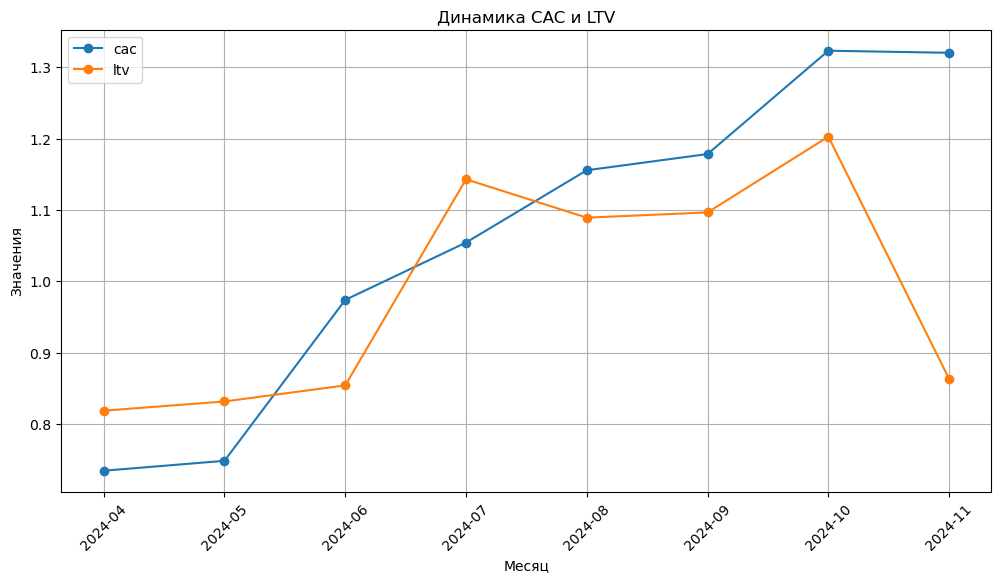

In [14]:
# на 28ой день 
max_lifetime=orders_LTV_CAC.groupby('first_month')['lifetime'].transform('max')
orders_LTV_CAC_group=orders_LTV_CAC[orders_LTV_CAC['lifetime']==max_lifetime]

# Построение графика
plt.figure(figsize=(12, 6))

plt.plot(avg_CAC['first_month'].astype(str), avg_CAC['cac'], marker='o', label='cac')
plt.plot(orders_LTV_CAC_group['first_month'].astype(str), orders_LTV_CAC_group['LTV'], marker='o', label='ltv')
plt.xticks(rotation=45)
plt.xlabel('Месяц')
plt.ylabel('Значения')
plt.title('Динамика CAC и LTV')
plt.legend()
plt.grid(True)
plt.show()

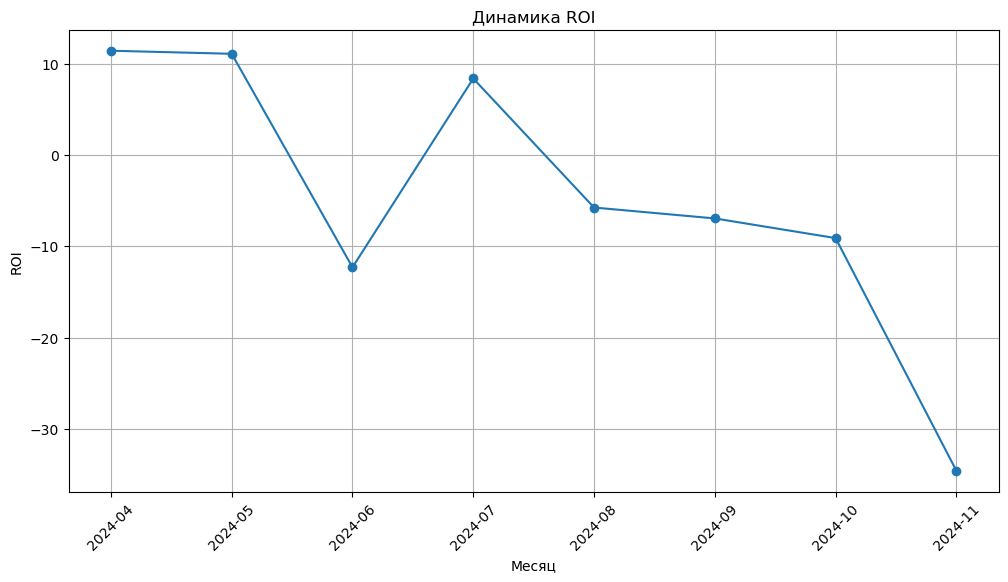

In [15]:

# Построение графика
plt.figure(figsize=(12, 6))

plt.plot(orders_LTV_CAC_group['first_month'].astype(str), orders_LTV_CAC_group['ROI'], marker='o')

plt.xticks(rotation=45)
plt.xlabel('Месяц')
plt.ylabel('ROI')
plt.title('Динамика ROI')
plt.grid(True)
plt.show()

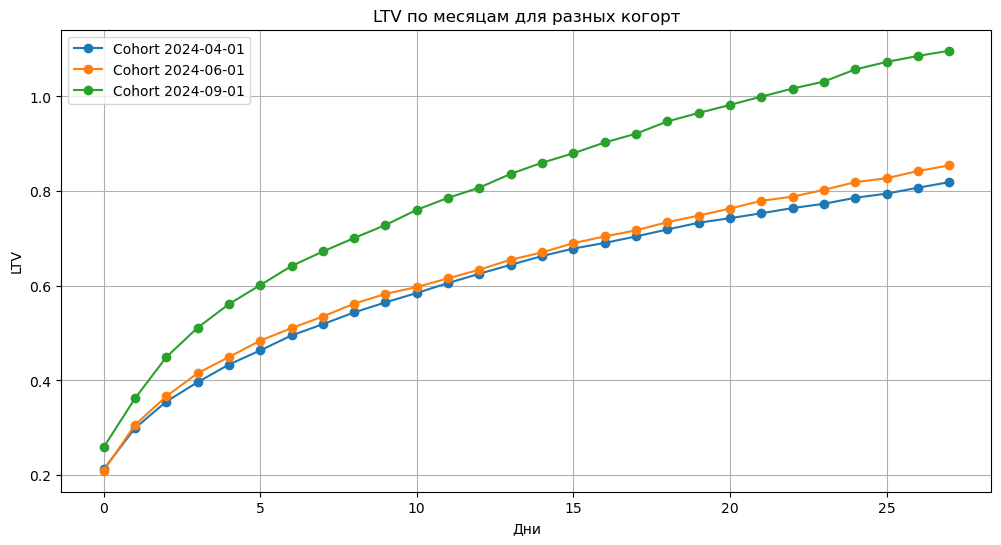

In [16]:
orders_LTV_CAC_group=orders_LTV_CAC.groupby(['first_month', 'lifetime'])['LTV'].mean().reset_index()

# Создадим график
plt.figure(figsize=(12, 6))

# Выберем когорты
first_months = ['2024-04-01', '2024-06-01', '2024-09-01']

# Построим линии для каждой когорты
for month in first_months:
  df_plot = orders_LTV_CAC_group[orders_LTV_CAC_group['first_month'] == month]
  plt.plot(df_plot['lifetime'], df_plot['LTV'], marker='o', label=f'Cohort {month}')


# Оформим график
plt.title('LTV по месяцам для разных когорт')
plt.xlabel('Дни')
plt.ylabel('LTV')
plt.legend()
plt.grid(True)
plt.show()


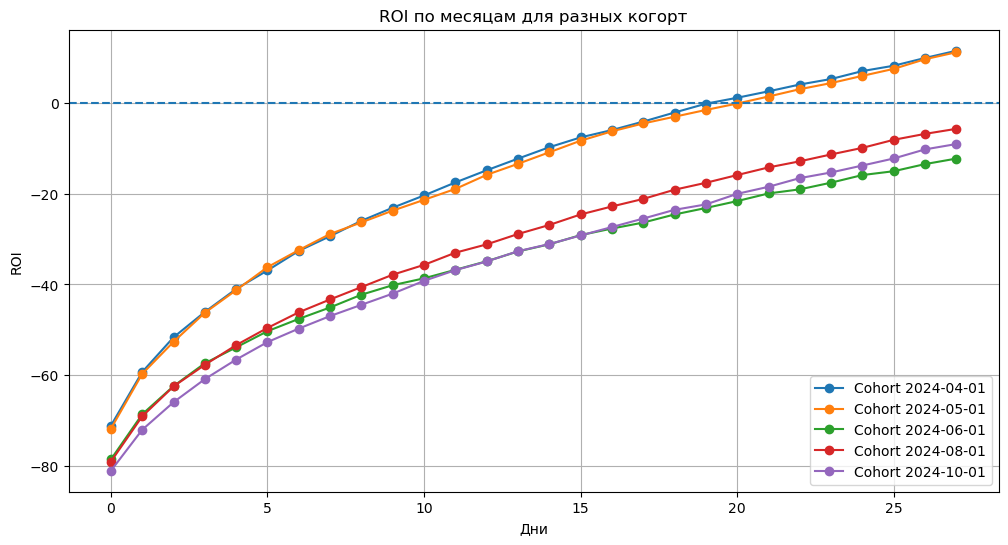

In [17]:
orders_LTV_CAC_group=orders_LTV_CAC.groupby(['first_month', 'lifetime'])['ROI'].mean().reset_index()

# Создадим график
plt.figure(figsize=(12, 6))

# Выберем когорты
first_months = ['2024-04-01', '2024-05-01', '2024-06-01', '2024-08-01', '2024-10-01']

# Построим линии для каждой когорты
for month in first_months:
  df_plot = orders_LTV_CAC_group[orders_LTV_CAC_group['first_month'] == month]
  plt.plot(df_plot['lifetime'], df_plot['ROI'], marker='o', label=f'Cohort {month}')

# Добавим линию, выше которой когорта окупается
plt.axhline(y=0, linestyle='--')

# Оформим график
plt.title('ROI по месяцам для разных когорт')
plt.xlabel('Дни')
plt.ylabel('ROI')
plt.legend()
plt.grid(True)
plt.show()

**Вывод:**  Несмотря на рост пользовательской активности, после запуска спортивного канала, финансовые показатели ухудшились. Средний САС увеличился примерно в 2 раза. LTV пользователя за 28 дней с июня по июль увеличился, потом происходит стагнация и с октября идет на спад. LTV пользователей не демонстрирует сопоставимого роста и остается ниже стоимости привлечения (затраты окупаются только в апреле, мае и июле). В результате ROI за 28 дней всех месячных когорт остается отрицательным (кроме как в 3х месях) и с июля ухудшается. 

## Анализ метрик в разрезе источника привлечения

Теперь необходимо разобраться, какие источники привлечения перспективны, а какие за 28 дней не окупились.

**Задача 1**. Определите самые популярные источники привлечения:
- Посчитайте общее число привлечённых пользователей для каждого источника.
- Визуализируйте динамику набора новых пользователей по дням в каждом источнике.
- Рассчитайте и визуализируйте динамику DAU, MAU и Stickiness по источникам привлечения.

**Задача 2**. Изучите динамику изменения метрик на 28-й день в разрезе источника. Проведите анализ с выделением недельных когорт по дате привлечения. Рассчитайте и визуализируйте:
- Скользящее удержание на 14-й день с момента привлечения (за период с 14-го по 28-й день).
- Конверсию в покупку.

Недельную динамику затрат на маркетинг по каждому источнику привлечения.
Динамику среднего CAC, значений LTV и ROI.

По результатам проведите анализ рекламных каналов. Дайте общую характеристику каждому рекламному каналу по рассчитанным метрикам. Укажите, какие рекламные каналы не вышли на уровень окупаемости за ожидаемый период, и предположите почему.


**Задача 1.**

Посчитаем общее число привлечённых пользователей для каждого источника.

In [18]:
display(visits.groupby('first_channel')['user_id'].nunique().reset_index().sort_values(by='user_id'))


,first_channel,user_id
1,MediaTornado,14080
2,RocketSuperAds,14257
3,TipTop,18118
0,FaceBoom,28401


Визуализируем динамику набора новых пользователей по дням в каждом источнике.

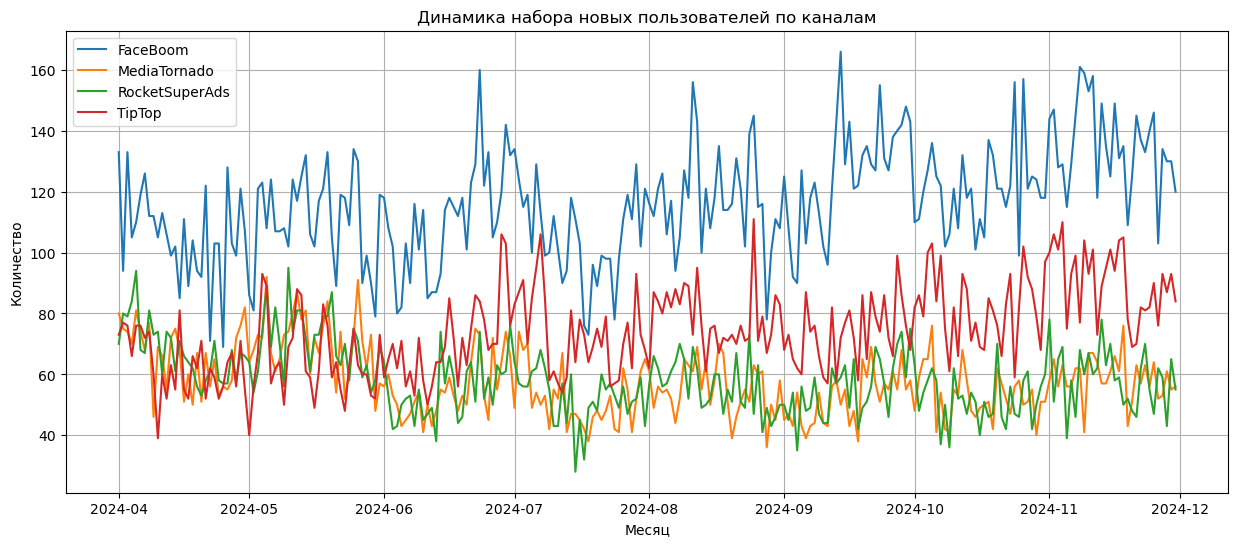

In [19]:
# Группировка по месяцам 
new_users_channel =visits.groupby(['first_dt', 'first_channel'])['user_id'].nunique().reset_index()

# Построение графика
plt.figure(figsize=(15, 6))

# Цикл для построения графиков по каналам
for channel in new_users_channel['first_channel'].unique():
   df_plot = new_users_channel[new_users_channel['first_channel'] == channel]
   plt.plot(df_plot['first_dt'], df_plot['user_id'], label=channel)

plt.xlabel('Месяц')
plt.ylabel('Количество')
plt.title('Динамика набора новых пользователей по каналам')
plt.legend()
plt.grid(True)
plt.show()

Рассчитаем и визуализируем динамику DAU, MAU и Stickiness по источникам привлечения.

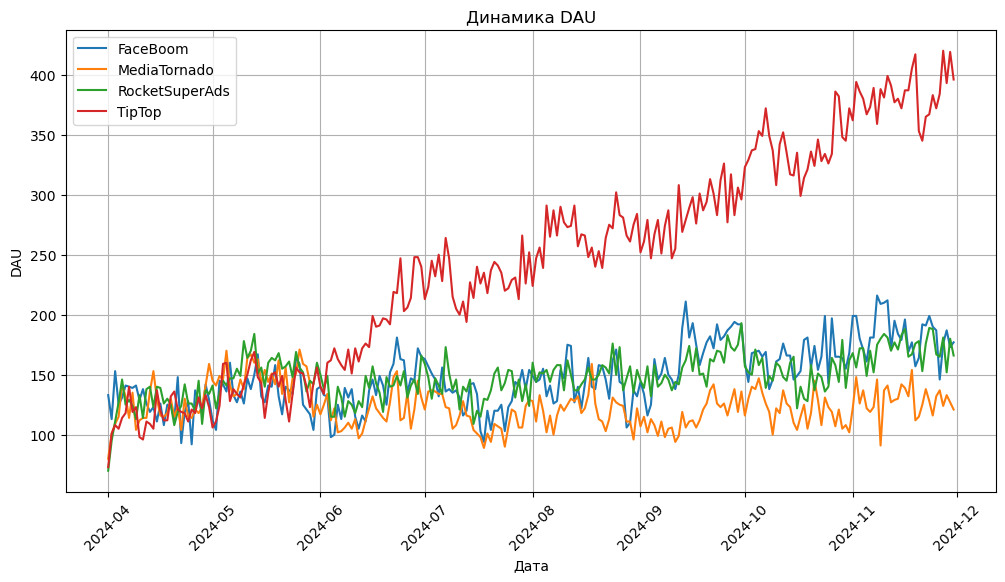

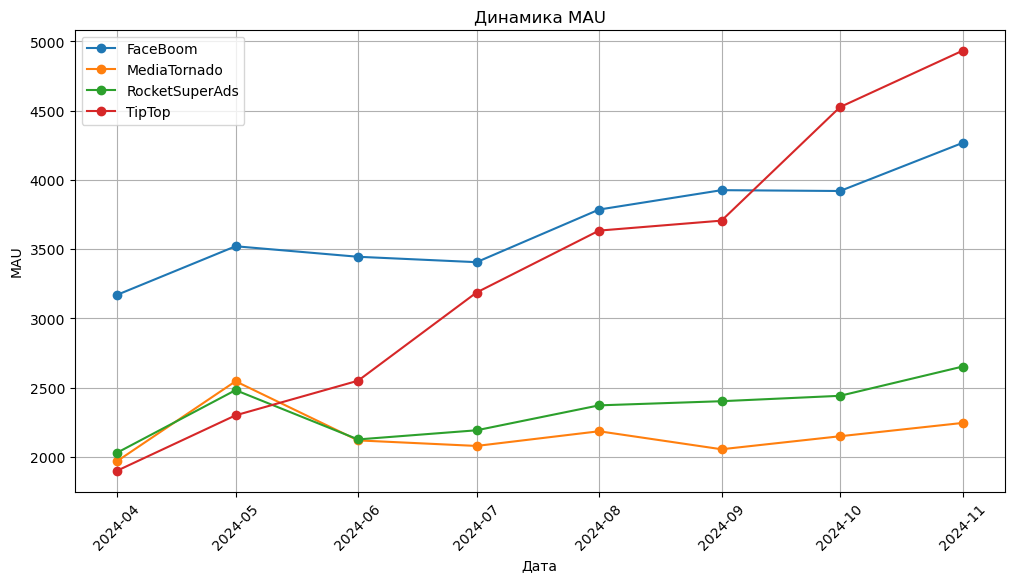

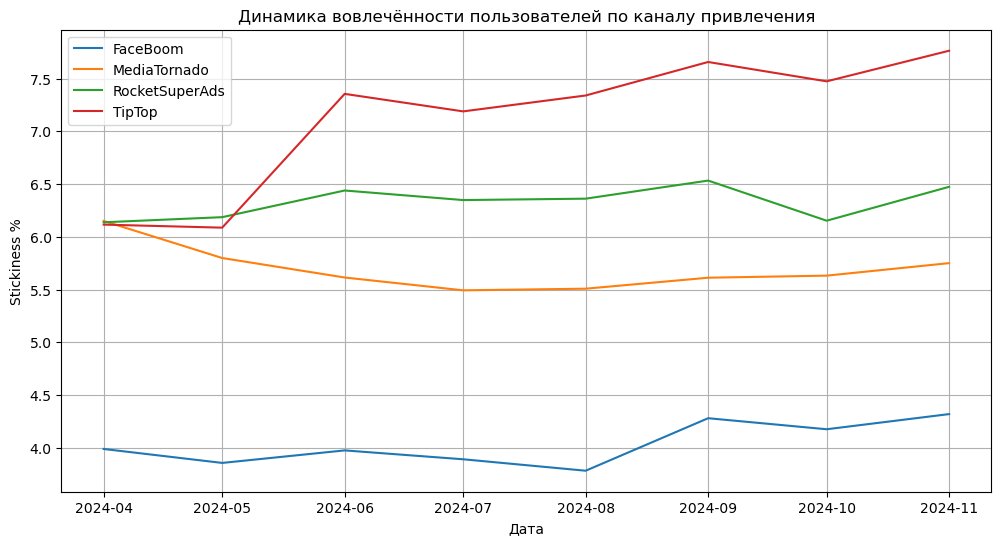

In [20]:
# DAU по дням
dau_channel=visits.groupby(['session_start', 'first_channel'])['user_id'].nunique().reset_index()
# MAU по месяцам
mau_channel = visits.groupby([visits['session_start'].dt.to_period('M'), 'first_channel'])['user_id'].nunique().reset_index()

# Построение графика
plt.figure(figsize=(12, 6))

# Цикл для построения графиков по каналам
for channel in dau_channel['first_channel'].unique():
    df_plot_dau = dau_channel[dau_channel['first_channel'] == channel]
    plt.plot(df_plot_dau['session_start'], df_plot_dau['user_id'], label=f'{channel}')

plt.xticks(rotation=45)
plt.xlabel('Дата')
plt.ylabel('DAU')
plt.title('Динамика DAU')
plt.grid(True)
plt.legend()
plt.show()

# Построение графика
plt.figure(figsize=(12, 6))

for channel in mau_channel['first_channel'].unique():
    df_plot_mau = mau_channel[mau_channel['first_channel'] == channel]
    plt.plot(df_plot_mau['session_start'].dt.to_timestamp(), df_plot_mau['user_id'],  marker='o', label=f'{channel}')
    
plt.xticks(rotation=45)
plt.xlabel('Дата')
plt.ylabel('МАU')
plt.title('Динамика МАU')
plt.grid(True)
plt.legend()
plt.show()


# Средний DAU по месяцам 
dau_avg_channel = dau_channel.groupby([dau_channel['session_start'].dt.to_period('M'), 'first_channel'])['user_id'].mean()

# Приводим к DataFrame с явными столбцами для удобства работы
dau_avg_df = dau_avg_channel.reset_index().rename(columns={'session_start': 'month', 'user_id': 'dau'})
mau_df = mau_channel.reset_index().rename(columns={'session_start': 'month'})

# Объединяем DAU и MAU по месяцу и каналу
Stickiness_channel = pd.merge(dau_avg_df, mau_df, on=['month', 'first_channel'], how='inner')

# Считаем Stickiness
Stickiness_channel['Stickiness'] = (Stickiness_channel['dau'] / Stickiness_channel['user_id']) * 100

 # Визуализация всех метрик на одном графике
plt.figure(figsize=(12, 6))
# Цикл для построения графиков по каналам
for channel in Stickiness_channel['first_channel'].unique():
    df_plot_Stickiness_channel = Stickiness_channel[Stickiness_channel['first_channel'] == channel]
    plt.plot(df_plot_Stickiness_channel['month'].dt.to_timestamp(), df_plot_Stickiness_channel['Stickiness'], label=f'{channel}')


plt.title('Динамика вовлечённости пользователей по каналу привлечения')
plt.xlabel('Дата')
plt.ylabel('Stickiness %')
plt.legend()
plt.grid(True)
plt.show()

**Вывод:** Канал привлечения FaceBoom самый массовый канал (больше 28000 пользователоей), канал привлечения  TipTop на втором месте (18000 пользователей). Каждый день в средне добавляется 120 новых пользователй. Наибольшая месячная активность у пользователей в канале привлечения FaceBoom и TipTop. Наибольшая дневная активность у пользователей в канале привлечения TipTop, при чем с июня пошло резкое увеличение дневной активности пользователей. Наибольшая вовлеченность пользователй по каналу привлечения TipTop, и после ввода нового кнтента в июне, вовлеченность только увеличивается - 7,5%. Что нельзя сказать про канал привлечения FaceBoom, хоть и по месячной активности пользователей этот канал лидер, но по вовлеченности у него показатели хуже всего -4%.

**Задача 2.**

Расчитаем скользящее удержание на 14-й день с момента привлечения (за период с 14-го по 28-й день).

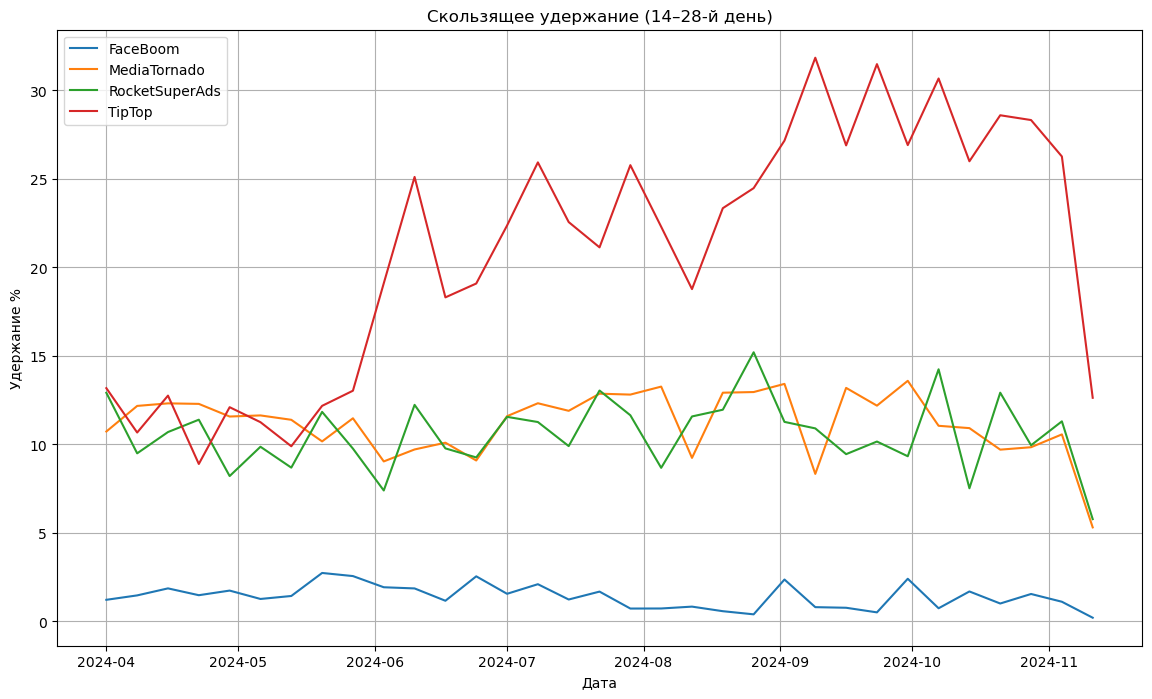

In [21]:
# Создание недельных когорт
visits['week_cohort'] =visits['first_dt'].dt.to_period('W')

# Фильтрация событий за 14–28 дней
retention_data = visits[(visits['lifetime'] >= 13) & (visits['lifetime'] <= 27)]
# Подсчёт активных пользователей
active_users = retention_data.groupby(['week_cohort', 'first_channel'])['user_id'].nunique().reset_index()
# Общее число пользователей в когорте
total_users = visits.groupby(['week_cohort', 'first_channel'])['user_id'].nunique().reset_index()
# Удержание = активные / общее × 100%
user = active_users.merge(total_users, on=['week_cohort', 'first_channel'], how='left')
user['retention_rate']=(user['user_id_x'] / user['user_id_y']) * 100

 # Визуализация всех метрик на одном графике
plt.figure(figsize=(14, 8))
# Цикл для построения графиков по каналам
for channel in user['first_channel'].unique():
    df_plot_user = user[user['first_channel'] == channel]
    plt.plot(df_plot_user['week_cohort'].dt.to_timestamp(), df_plot_user['retention_rate'], label=f'{channel}')


plt.title('Скользящее удержание (14–28‑й день)')
plt.xlabel('Дата')
plt.ylabel('Удержание %')
plt.legend()
plt.grid(True)
plt.show()



Расчитаем конверсию в покупку.

,week_cohort,first_channel,user_id_x,user_id_y,convertion
0,2024-04-01/2024-04-07,FaceBoom,93,820,11.341463
1,2024-04-01/2024-04-07,MediaTornado,24,522,4.597701
2,2024-04-01/2024-04-07,RocketSuperAds,45,542,8.302583
3,2024-04-01/2024-04-07,TipTop,48,516,9.302326
4,2024-04-08/2024-04-14,FaceBoom,78,749,10.413885
...,...,...,...,...,...
135,2024-11-18/2024-11-24,TipTop,84,567,14.814815
136,2024-11-25/2024-12-01,FaceBoom,66,763,8.650066
137,2024-11-25/2024-12-01,MediaTornado,11,341,3.225806
138,2024-11-25/2024-12-01,RocketSuperAds,25,331,7.552870


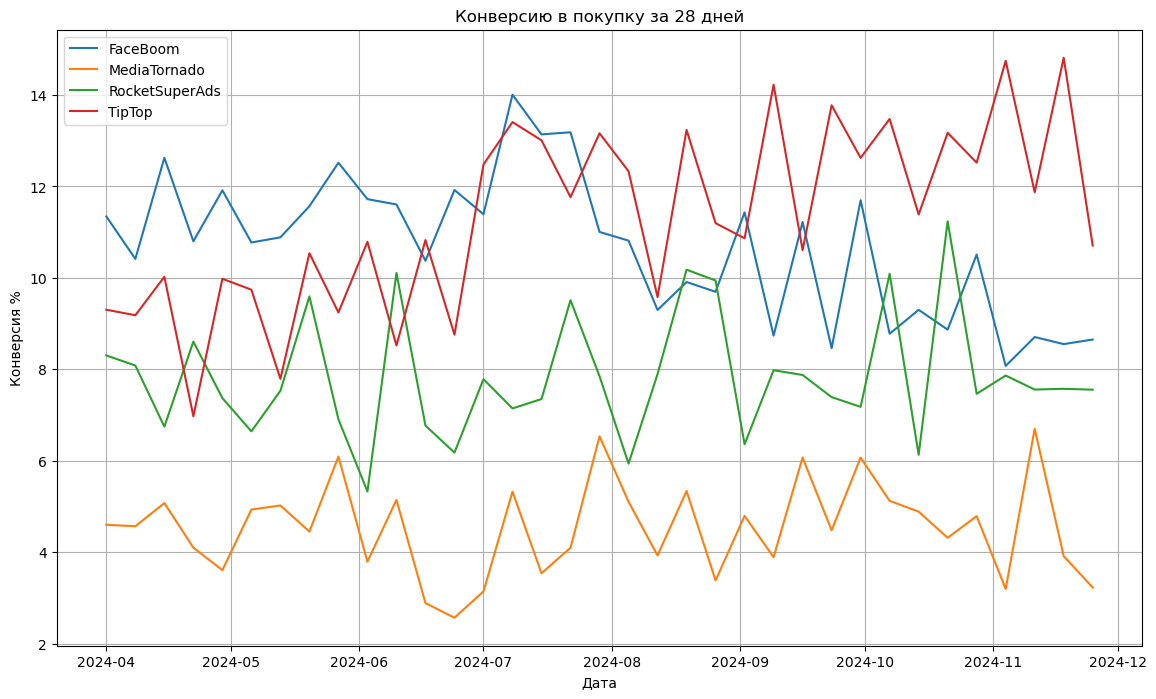

In [22]:
orders['week_cohort'] =orders['first_dt'].dt.to_period('W')
# Покупки за 28 дней
purchases_28d = orders[orders['lifetime'] <= 27]
# Уникальные покупатели по когортам
buyers = purchases_28d.groupby(['week_cohort', 'first_channel'])['user_id'].nunique().reset_index()
user_conv = buyers.merge(total_users, on=['week_cohort', 'first_channel'], how='left')
# Конверсия = покупатели / общее число × 100%
user_conv['convertion']=(user_conv['user_id_x'] /user_conv['user_id_y']) * 100
display(user_conv)

 # Визуализация всех метрик на одном графике
plt.figure(figsize=(14, 8))
# Цикл для построения графиков по каналам
for channel in user_conv['first_channel'].unique():
    df_plot_user = user_conv[user_conv['first_channel'] == channel]
    plt.plot(df_plot_user['week_cohort'].dt.to_timestamp(), df_plot_user['convertion'], label=f'{channel}')


plt.title('Конверсию в покупку за 28 дней')
plt.xlabel('Дата')
plt.ylabel('Конверсия %')
plt.legend()
plt.grid(True)
plt.show()

**Вывод:** Наиболее высокое удержание пользоватеолей показывает канал удержания - TipTop. После июня оно выросло до 30%. Худшие показатели удержания у FaceBoom - 2-3%.
Самая высокая конверсия в покупку наблюдается у пользовтаелей, привлеченных через TipTop - 15%, и на всем исследуемом периоде конверсия растет. Самая низкая конверсия в канале привлечения MediaTornado - 4%. У пользователей, привлеченных по каналу FaceBoom видно снижение конверсии с июля.

Расчитаем недельную динамику затрат на маркетинг по каждому каналу привлечения.

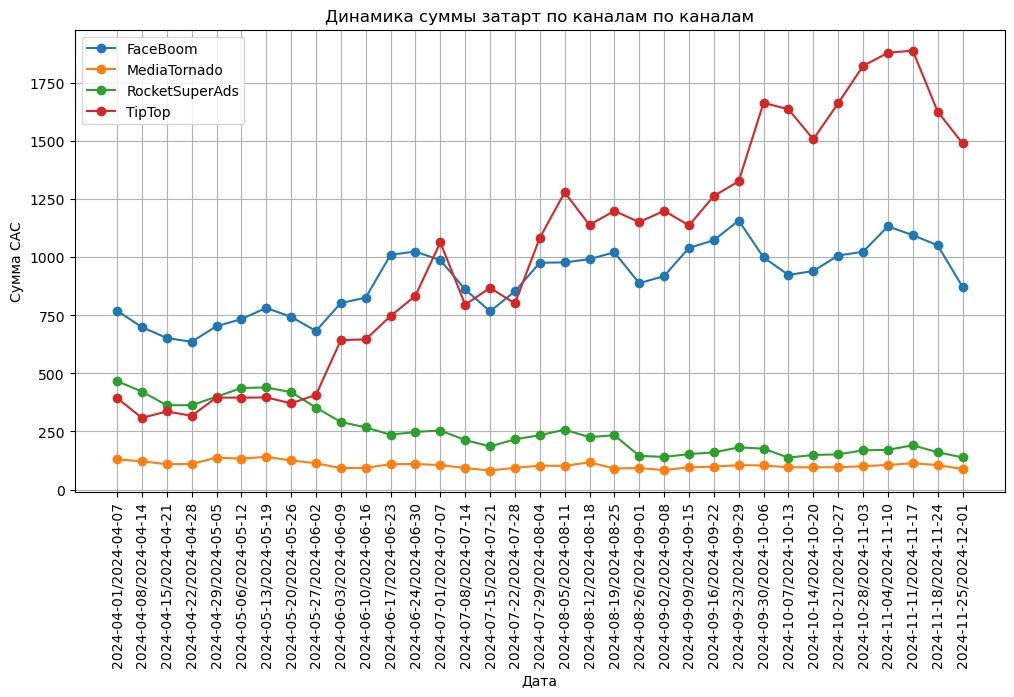

In [23]:
profiles['week_cohort']=profiles['first_dt'].dt.to_period('W')

avg_CAC_cohort_sum=profiles.groupby(['first_channel', 'week_cohort'])['cac'].sum().reset_index()
# Построение графика
plt.figure(figsize=(12, 6))

# Цикл для построения графиков по каналам
for channel in avg_CAC_cohort_sum['first_channel'].unique():
   df_plot = avg_CAC_cohort_sum[avg_CAC_cohort_sum['first_channel'] == channel]
   plt.plot(df_plot['week_cohort'].astype(str), df_plot['cac'], marker='o', label=channel)

plt.xticks(rotation=90)
plt.xlabel('Дата')
plt.ylabel('Сумма CAC')
plt.title('Динамика суммы затарт по каналам по каналам')
plt.legend()
plt.grid(True)
plt.show()

Расчитаем динамику среднего CAC, значений LTV и ROI и визуализируем.

In [24]:

# Посчитаем CAC для каждого месяца
avg_CAC_cohort=profiles.groupby(['first_channel', 'week_cohort'])['cac'].mean().reset_index()

# Суммируем revenue для каждого месяца
orders_LTV_cohort=orders.groupby(['first_channel', 'week_cohort', 'lifetime'])['revenue'].sum().reset_index()
# количество пользователей в когорте
cohort_size_cohort = profiles.groupby(['first_channel', 'week_cohort'])['user_id'].nunique().reset_index(name='user_count')
# добавим в таблицу
orders_LTV_cohort = orders_LTV_cohort.merge(cohort_size_cohort, on=['first_channel', 'week_cohort'], how='left')
# кумулятивная выручка
orders_LTV_cohort['cum']=orders_LTV_cohort.groupby(['first_channel', 'week_cohort'])['revenue'].cumsum()
# Посчитаем LTV для каждого месяца
orders_LTV_cohort['LTV']=orders_LTV_cohort['cum']/orders_LTV_cohort['user_count']

# Посчитаем ROI для каждого месяца
orders_LTV_CAC_cohort=orders_LTV_cohort.merge(avg_CAC_cohort, on=['first_channel', 'week_cohort'], how='left')
orders_LTV_CAC_cohort['ROI']=(orders_LTV_CAC_cohort['LTV']/orders_LTV_CAC_cohort['cac']-1)*100
orders_LTV_CAC_cohort=orders_LTV_CAC_cohort.sort_values(by=['first_channel', 'week_cohort'])

# Фильтруем транзакции — только те, что в пределах 28 дней от first_dt
orders_LTV_CAC_cohort_28=orders_LTV_CAC_cohort[orders_LTV_CAC_cohort['lifetime']<28]
display(orders_LTV_CAC_cohort_28)


,first_channel,week_cohort,lifetime,revenue,user_count,cum,LTV,cac,ROI
0,FaceBoom,2024-04-01/2024-04-07,0,239.80,820,239.80,0.292439,0.938873,-68.852123
1,FaceBoom,2024-04-01/2024-04-07,1,40.37,820,280.17,0.341671,0.938873,-63.608421
2,FaceBoom,2024-04-01/2024-04-07,2,14.95,820,295.12,0.359902,0.938873,-61.666549
3,FaceBoom,2024-04-01/2024-04-07,3,8.97,820,304.09,0.370841,0.938873,-60.501426
4,FaceBoom,2024-04-01/2024-04-07,4,14.96,820,319.05,0.389085,0.938873,-58.558256
...,...,...,...,...,...,...,...,...,...
8712,TipTop,2024-11-25/2024-12-01,1,100.70,523,274.72,0.525277,2.849443,-81.565618
8713,TipTop,2024-11-25/2024-12-01,2,44.85,523,319.57,0.611033,2.849443,-78.556074
8714,TipTop,2024-11-25/2024-12-01,3,32.90,523,352.47,0.673939,2.849443,-76.348404
8715,TipTop,2024-11-25/2024-12-01,4,29.92,523,382.39,0.731147,2.849443,-74.340699


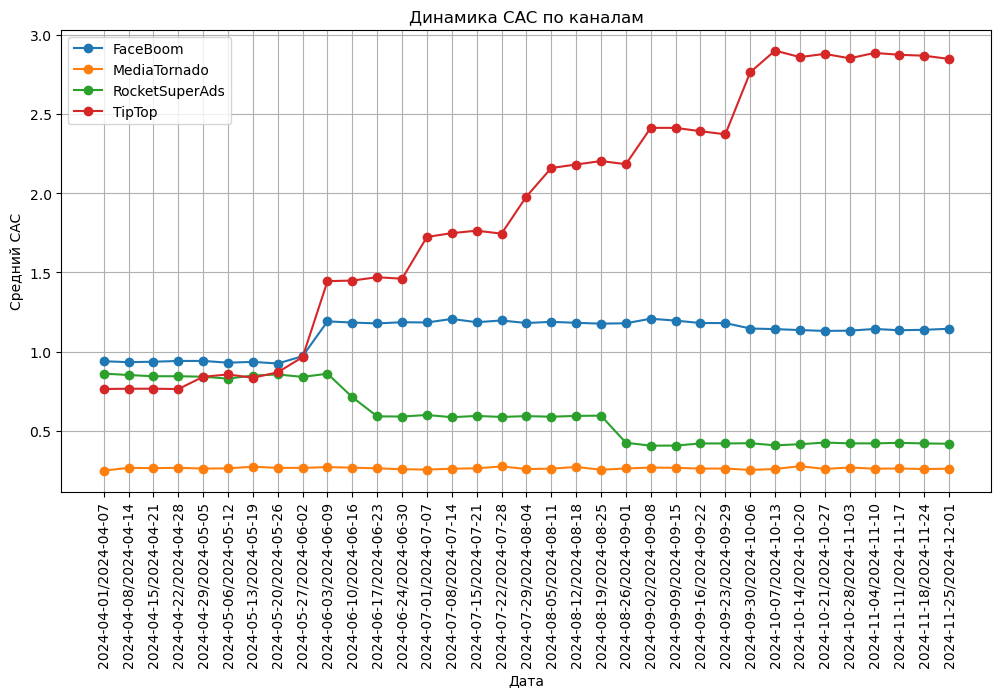

In [25]:

# Построение графика
plt.figure(figsize=(12, 6))

# Цикл для построения графиков по каналам
for channel in avg_CAC_cohort['first_channel'].unique():
   df_plot = avg_CAC_cohort[avg_CAC_cohort['first_channel'] == channel]
   plt.plot(df_plot['week_cohort'].astype(str), df_plot['cac'], marker='o', label=channel)

plt.xticks(rotation=90)
plt.xlabel('Дата')
plt.ylabel('Средний CAC')
plt.title('Динамика CAC по каналам')
plt.legend()
plt.grid(True)
plt.show()

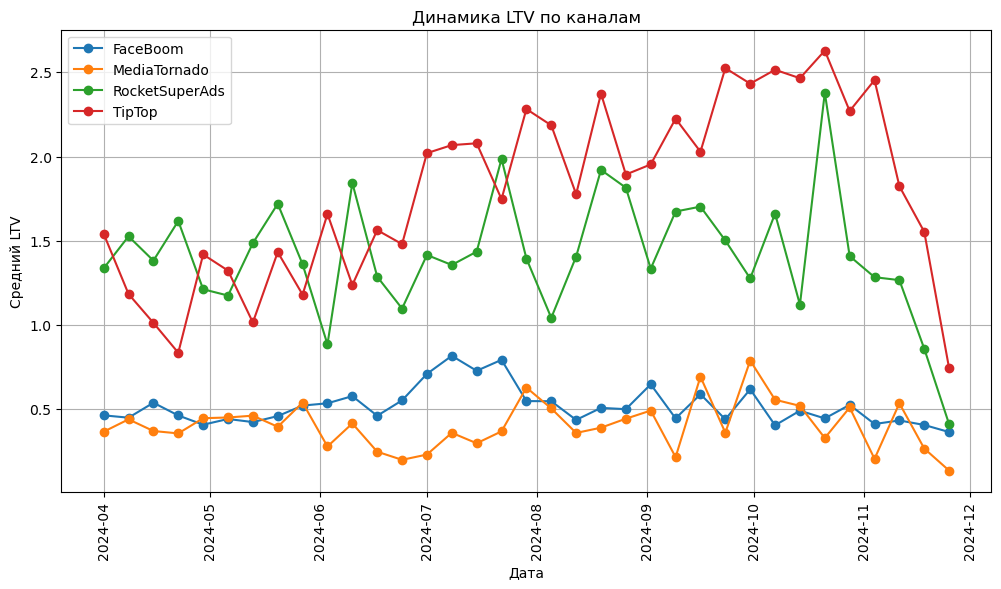

In [26]:
# Построение графика
plt.figure(figsize=(12, 6))
# на 28ой день 
max_lifetime=orders_LTV_CAC_cohort_28.groupby(['first_channel', 'week_cohort'])['lifetime'].transform('max')
orders_LTV_CAC_cohort28=orders_LTV_CAC_cohort_28[orders_LTV_CAC_cohort_28['lifetime']==max_lifetime]
# Цикл для построения графиков по каналам
for channel in orders_LTV_CAC_cohort28['first_channel'].unique():
   df_plot = orders_LTV_CAC_cohort28[orders_LTV_CAC_cohort28['first_channel'] == channel]
   plt.plot(df_plot['week_cohort'].dt.start_time, df_plot['LTV'], marker='o', label=channel)

plt.xticks(rotation=90)
plt.xlabel('Дата')
plt.ylabel('Средний LTV')
plt.title('Динамика LTV по каналам')
plt.legend()
plt.grid(True)
plt.show()

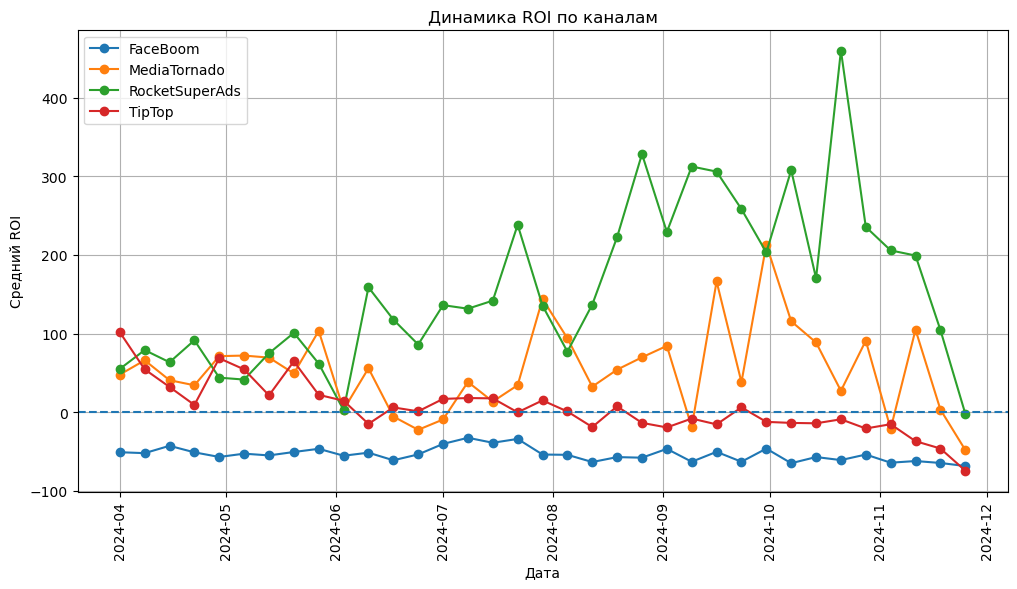

In [27]:
# Построение графика
plt.figure(figsize=(12, 6))

# Цикл для построения графиков по каналам
for channel in orders_LTV_CAC_cohort28['first_channel'].unique():
   df_plot = orders_LTV_CAC_cohort28[orders_LTV_CAC_cohort28['first_channel'] == channel]
   plt.plot(df_plot['week_cohort'].dt.start_time, df_plot['ROI'], marker='o', label=channel)
# Добавим линию, выше которой когорта окупается
plt.axhline(y=0, linestyle='--')
plt.xticks(rotation=90)
plt.xlabel('Дата')
plt.ylabel('Средний ROI')
plt.title('Динамика ROI по каналам')
plt.legend()
plt.grid(True)
plt.show()

**Вывод:** Самые большие затраты на маркетинг по каналу TipTop, с каждым месяцем они растут и достигают 2,8. Наименьше затраты - MediaTornado, они стабильны на всем периоде и равны 0,2. LTV по каналам привлечеиня FaceBoom и MediaTornado стабильно на всем периоде и примерно равно 0,5. По каналу TipTop  LTV растет на всем промежутке и начинает снижаться с ноября. ROI для канала FaceBoom на всем периоде стабилен, не растет и меньше 0. В канале RocketSuperAds ROI за 28дней на всем наблюдаемом периоде. Для канала TipTop ROI с июля стал хуже и перестал окупаться за 28дней. Для канала  RocketSuperAds после запкуска нового контента ROI стал расти, но после октября резко стал снижаться.

## Анализ периода окупаемости маркетинговых вложений

Для источников, которые к 28-му дню не выходят на уровень окупаемости, рассчитайте и визуализируйте в виде тепловой карты значения ROI за больший период, например за 8–10 недель.

Разделите данные на недельные когорты по дате привлечения, в качестве интервала наблюдений используйте недели.

Сделайте вывод о том, за какой период окупаются вложения в эти источники.

Построим тепловую карту для канала привлечения TipTop, так как после запуска нового контента в августе перестали окупаться затраты на маркетинг за 28 дней

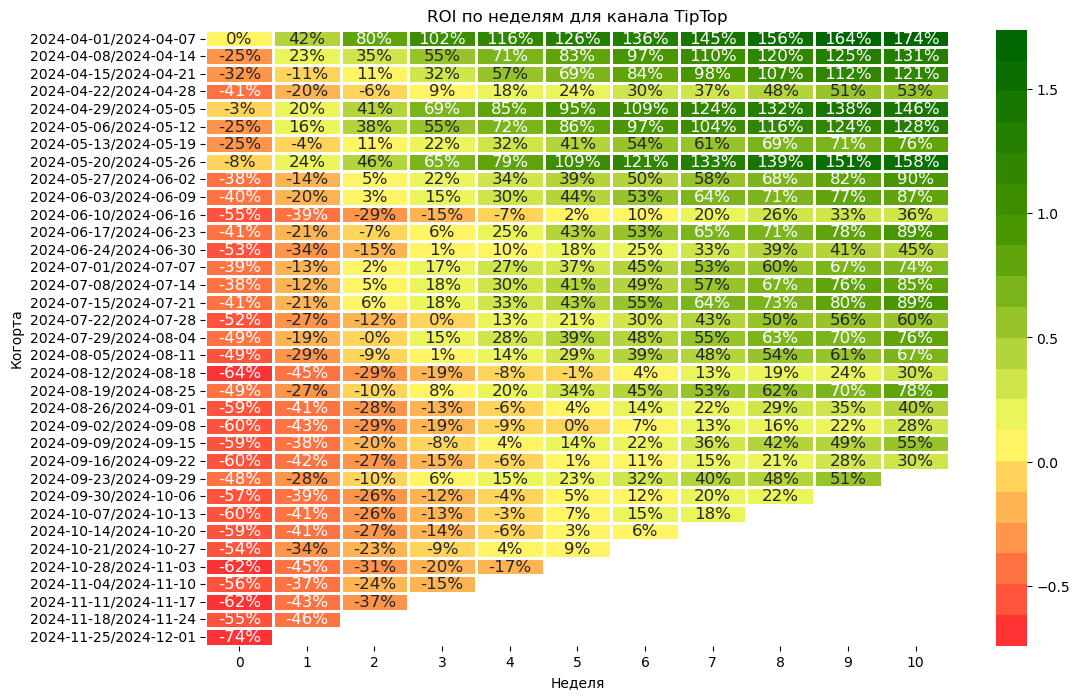

In [28]:
orders_LTV_CAC_cohort['w_number'] = orders_LTV_CAC_cohort['lifetime']//7
orders_LTV_CAC_cohort=orders_LTV_CAC_cohort[orders_LTV_CAC_cohort['w_number']<=10] 

# # Для каждой когорты посчитае значение ROI
max_lifetime=orders_LTV_CAC_cohort.groupby(['week_cohort', 'first_channel', 'w_number'])['lifetime'].transform('max')
orders_LTV_CAC_cohort_max=orders_LTV_CAC_cohort[orders_LTV_CAC_cohort['lifetime']==max_lifetime]

# Отфильтруем интересующий нас канал
orders_LTV_CAC_cohort_max_TipTop  = orders_LTV_CAC_cohort_max [orders_LTV_CAC_cohort_max ['first_channel'] == 'TipTop'].copy()
# Для корректного отображения процентов сдвинем запятую на 2 знака влево
orders_LTV_CAC_cohort_max_TipTop['ROI'] = orders_LTV_CAC_cohort_max_TipTop['ROI'] / 100
# Пивотируем данные, чтобы first_month был индексом, а N_month — столбцом
df_pivot =orders_LTV_CAC_cohort_max_TipTop.pivot(index='week_cohort', columns='w_number', values='ROI')
# Заменим нули на NaN для корректной отрисовки
df_pivot[df_pivot == 0] = float('nan')

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900', '#006600'], N=20)

# Построим heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(df_pivot,
          cmap=cmap,
          annot=True,
          fmt='.0%',
          linewidths=2,
          annot_kws={"size": 12})


plt.title('ROI по неделям для канала TipTop')
plt.xlabel('Неделя')
plt.ylabel('Когорта')
plt.show()

Как видим по тепловой карте,затраты на когорты, которые пришли до 12 августа - окупаются за 3 недели, в остальных когортах - окупаемость за 5 недель.

Построим тепловую карту для канала привлечения FaceBoom, так как затраты на маркетинг за 28 дней не окупаются на протяжении всего периода наблюдения.

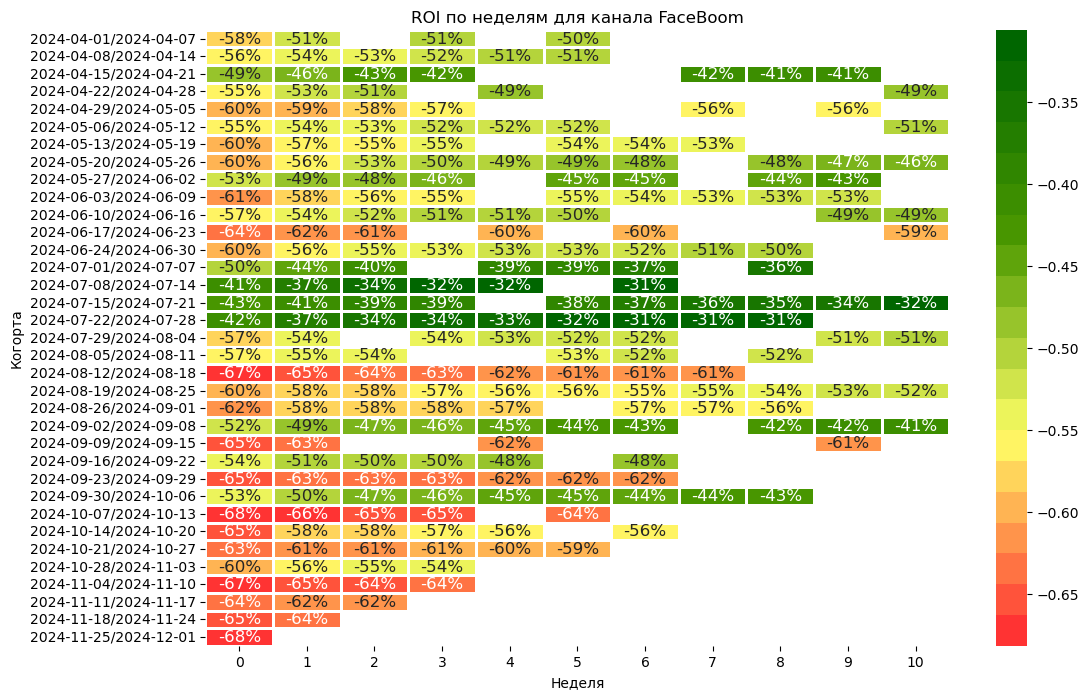

In [29]:
orders_LTV_CAC_cohort['w_number'] = orders_LTV_CAC_cohort['lifetime']//7
orders_LTV_CAC_cohort=orders_LTV_CAC_cohort[orders_LTV_CAC_cohort['w_number']<=10] 

# # Для каждой когорты посчитае значение ROI
max_lifetime=orders_LTV_CAC_cohort.groupby(['week_cohort', 'first_channel', 'w_number'])['lifetime'].transform('max')
orders_LTV_CAC_cohort_max=orders_LTV_CAC_cohort[orders_LTV_CAC_cohort['lifetime']==max_lifetime]

# Отфильтруем интересующий нас канал
orders_LTV_CAC_cohort_max_FaceBoom  = orders_LTV_CAC_cohort_max [orders_LTV_CAC_cohort_max ['first_channel'] == 'FaceBoom'].copy()
# Для корректного отображения процентов сдвинем запятую на 2 знака влево
orders_LTV_CAC_cohort_max_FaceBoom['ROI'] = orders_LTV_CAC_cohort_max_FaceBoom['ROI'] / 100
# Пивотируем данные, чтобы first_month был индексом, а N_month — столбцом
df_pivot =orders_LTV_CAC_cohort_max_FaceBoom.pivot(index='week_cohort', columns='w_number', values='ROI')
# Заменим нули на NaN для корректной отрисовки
df_pivot[df_pivot == 0] = float('nan')

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900', '#006600'], N=20)

# Построим heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(df_pivot,
          cmap=cmap,
          annot=True,
          fmt='.0%',
          linewidths=2,
          annot_kws={"size": 12})


plt.title('ROI по неделям для канала FaceBoom')
plt.xlabel('Неделя')
plt.ylabel('Когорта')
plt.show()

Как видим по тепловой карте, затраты на маркетинг не окукпаются даже за 10 недель.

## Выводы и рекомендации

Сформулируйте общий вывод. Зафиксируйте основные результаты и инсайты. Например, охарактеризуйте аудиторию продукта, покажите распределение маркетинговых затрат по каналам привлечения, опишите каждый канал привлечения. Делайте акцент на сильных и слабых сторонах. Укажите, какие каналы привлечения не вышли на окупаемость и по каким причинам.

Дайте рекомендации отделу маркетинга: опишите, как повысить эффективность вложений в рекламу.


Характеристика каналов:
FaceBoom:

        +самый большой объем трафика
        +постоянный приток пользоватеелй
        -низкая вовлеченность
        -низкий ROI

TipTop:

        +высокое удержание
        +высокая конверсия
        +высокий LTV
        -после июня резко вырос САС
        -из-за высоких затрат на привлечения ухудшился ROI

MediaTornado:

        +самый низкий САС
        -низкая конверсия
        -низкий LTV
        
RocketSuperAds:

        +хорошее удержание
        +высокий LTV
        +лучший ROI 
        -невысокая активность пользователей

После запуска спортивного контента, приложению удалось увеличить пользовательскую активность и привлечь больше новых пользователей. MAU, DAU и показатели вовлеченности демонстрируют положительную динамику.

Однако рост аудитории не привел к соответствующему росту выручки. Основной причиной стало существенное увеличение затрат на привлечение пользователей, особенно по каналу TipTop.

Несмотря на хорошие показатели удержания, конверсии и LTV у пользователей TipTop, стоимость их привлечения выросла быстрее, чем доходность. В результате ROI большинства когорт остается отрицательным даже через 28 дней после привлечения.

Ни один из рекламных каналов не демонстрирует устойчивой окупаемости на требуемом горизонте в 28 дней. Наиболее перспективным выглядит RocketSuperAds благодаря относительно высокому LTV и лучшему уровню ROI. Каналы FaceBoom и MediaTornado привлекают пользователей дешевле или в большем объеме, но качество аудитории оказывается недостаточным для достижения окупаемости.

Для повышения эффективности маркетинга рекомендуется перераспределить рекламный бюджет в пользу наиболее качественных каналов, пересмотреть объем инвестиций в TipTop, а также сосредоточиться на повышении конверсии и монетизации пользователей в первые недели после привлечения.